In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import sklearn
from sklearn import datasets
sklearn.set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, RobustScaler, MinMaxScaler, Normalizer
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score

# 차원 축소(dimension reduction)

피쳐는 중요한 부분과 중요하지 않은 부분이 존재한다.  
중요하지 않은 부분을 노이즈(noise, 잡음)라 하며 노이즈는 데이터에서 정보를 얻을 때 방해가 되는 부분을 의미한다. `머신러닝` 과정에서 `불필요한 노이즈를 제거`하는 것이 중요하고 노이즈를 제거할 때 사용하는 방법이 `차원 축소`이다. 차원 축소를 통해 데이터의 중요하지 않은 부분이 노이즈를 제거할 수 있기에 널리 사용되고 있다.

차원 축소는 주어진 데이터의 `정보 손실을 최소화`하면서 차원을 줄이는 것이 핵심이다. 차원 축소는 특징을 추출한다는 것과 밀접한 관련이 있고 특징을 추출한다는 것은 데이터에서 두드러진 면을 찾는 것과 같다.

차원 축소는 비지도 학습, 지도 학습과 마찬가지로 비지도 학습 차원 축소로 접근할 수 있고, 지도 학습 차원 축소로 접근할 수도 있다. 비지도 학습적인 접근 방법에는 대표적인 방법으로 주성분 분석(Principal Component Analysis, PCA)과 같은 방법이 있고, 지도 학습적인 접근 방법에는 선형 판변 분석(Linear Discriminant Analysis, LDA)과 같은 방법이 있다.

# 차원의 저주(curse of dimensionality)  

차원 축소를 하는 이유 중 하나는 차원의 저주 문제를 해결할 수 있기 때문이다. 차원의 저주란 데이터의 차원(피쳐의 개수)이 커질수록 해당 차원을 표현하기 위해 필요한 `데이터가 기하급수적으로 많아짐`을 의미한다. 학습 데이터셋의 차원이 클 수록 차원의 저주 때문에 해당 공간을 적절히 표현하지 못하여 `과적합될 확률이 높아`진다.

주성분 분석은 차원 축소 방법의 하나로 여러 피쳐가 통계적으로 `상관 관계가 없도록 변환`시키는 방법이다.

주성분 분석은 피쳐 간 상관 관계를 기반으로 데이터의 특성을 파악한다.  
먼저 데이터셋의 공분산 행렬의 고유값과 고유 벡터를 구한다. 이때, 고유값은 고유 벡터의 크기를 나타내며 분산의 크기를 의미한다. 또한 고유 벡터는 분산의 방향을 의미한다. 분산이 큰 고유 벡터에 기존 데이터를 투영해서 새로운 벡터를 구할 수 있는데, 이렇게 구한 벡터를 주성분 벡터라 부른다.

공분산을 안다는 것은 상관 계수도 알 수 있다는 뜻이다. 고유 벡터를 통해 알 수 있는 사실은 각 피쳐의 분산 방향을 알 수 있고 고유값을 통해서는 분산의 크기를 알 수 있다. 즉, 데이터가 여러 방향으로 흩어져 있을때, 고유 벡터를 사용하면 각 흩어짐에 대한 방향을 파악할 수 있이며, 고유값을 이용하면 어느 정도 흩어져 있는지 그 크기를 확인할 수 있다는 뜻이다.

공분산의 행렬 $p$차원이라면 고유값도 $p$개를 구할 수 있다. 고유값은 데이터의 흩어진 정도의 크기라고 했으므로 $p$개를 모두 더하면 데이터셋 전체 변동성이 된다. 전체 변동성 대비 $i$번째 주성분이 설명하는 비율을 수식으로 나타내면 아래와 같다.

$$\frac {\lambda_i} {\lambda_1 + \lambda_2 + \lambda_3 + \dots + \lambda_p}$$

위 식을 사용하면 해당 고유값이 전체 변동성의 크기 중 어느 정도를 설명하는지 알 수 있다. 이를 설명된 분산(explained variance)이라고 한다. 예를들면 $p$차원의 데이터를 2차원으로 줄이기로 한다면, 가장 큰 고유값 2개를 $\lambda_1, \lambda_2$라고 하고 설명된 분산을 구하기 위해 아래 처럼 구했다 가정하면

$$\frac {\lambda_1 + \lambda_2} {\lambda_1 + \lambda_2 + \lambda_3 + \dots + \lambda_p} = 0.94$$

위 결과를 통해 $\lambda_1, \lambda_2$로 설명되는 변동성이 94%라는 것을 알 수 있다. 즉, 전체 $p$차원의 데이터를 2차원으로 줄였을 때, 전체 변동성의 94%가 설명 가능하다는 것이다.

# 주성분 분석(Principal Component Analysis, PCA)

차원(피처의 개수)을 줄이면서도 데이터가 분포된 정도(분산)는 최대한 유지되게 만들어서 고차원 데이터를 저차원 데이터로 차원을 축소하는 알고리즘이다.  
주로 고차원 데이터를 3차원 이하의 데이터로 바꿔 시각화하는데 많이 사용되며, 유용한 정보만 살려서 적은 메모리에 적용하거나 노이즈(잡음)를 줄이고 싶을때도 사용되는 알고리즘이다.

<img src="./pca1.png" wigth="1300" align="left" />
<img src="./pca2.png" wigth="1300" align="left" />
<img src="./pca3.png" wigth="1300" align="left" />
<img src="./pca4.png" wigth="1300" align="left" />

## 적당한 데이터셋을 만든다.

In [2]:
datas = np.array([[5 * x, 5 * (np.sqrt(1/ 3) + 0.1 * np.random.normal(0, 1)) * x] for x in np.random.normal(0, 1, 15)])
# print(datas)
n_datas = datas - np.mean(datas, axis=0)
# print(n_datas)

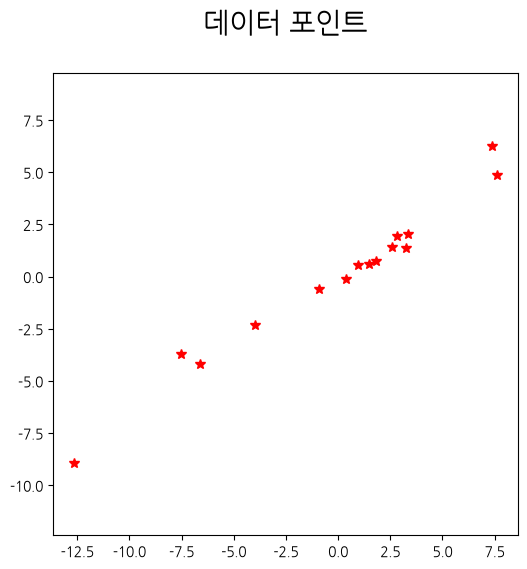

In [3]:
plt.figure(figsize=[6, 6])
plt.plot(n_datas[:, 0], n_datas[:, 1], '*r', markersize=7)
plt.title('데이터 포인트', pad=30, fontsize=20)
plt.axis('equal') # 각 축의 범위와 스케일을 동일하게 처리한다.
plt.show()

## 행렬 내적

넘파이의 dot(), matmul() 메소드로 행렬의 내적을 계산할 수 있다.  
두 항이 모두 넘파이 배열일 경우 넘파이의 행렬 내적 연산자 `@`를 사용할 수 있다.

In [4]:
A = np.array([[1, 2], [3, 4]])
print('A\n', A, sep='')
B = np.array([[1, -2], [2, 3]])
print('B\n', B, sep='')
print('-' * 100)
print('AB\n', np.dot(A, B), sep='')
print('AB\n', np.matmul(A, B), sep='')
print('AB\n', A @ B, sep='')

A
[[1 2]
 [3 4]]
B
[[ 1 -2]
 [ 2  3]]
----------------------------------------------------------------------------------------------------
AB
[[ 5  4]
 [11  6]]
AB
[[ 5  4]
 [11  6]]
AB
[[ 5  4]
 [11  6]]


## 벡터 내적

X축으로 사영하면 Y좌표는 무시되고(0이되고) X좌표만 남는다.

In [5]:
# 1행 2열 벡터를 만든다. => 행이 1개이므로 행 벡터라 부른다.
# print(np.array([1, 0]))
# 15행 2열인 2차원 배열(n_datas)을 행 벡터 [1, 0]와 내적하면 결과는 데이터가 15개인 1차원 배열이 된다.
proj1_x = n_datas @ np.array([1, 0])
# print(proj1_x)
# reshape(-1, n)는 행의 개수는 상황에 따라 적절히 만들고 열의 개수는 무조건 n개로 고정한다.
# 데이터가 15개인 1차원 배열에 reshape(-1, 1) 메소드를 실행하면 15행 1열인 2차원 배열이 된다.
print(proj1_x.reshape(-1, 1))

[[  2.83502387]
 [ -3.96400284]
 [  0.97307882]
 [  3.26678166]
 [  7.37876759]
 [  1.80520583]
 [  1.49512954]
 [  7.59520479]
 [ -6.61568993]
 [  2.60094208]
 [ -0.90880122]
 [-12.66084402]
 [  0.35861584]
 [ -7.52279675]
 [  3.36338474]]


In [6]:
proj2_x = proj1_x.reshape(-1, 1) @ np.array([[1, 0]])
print(proj2_x)

[[  2.83502387   0.        ]
 [ -3.96400284   0.        ]
 [  0.97307882   0.        ]
 [  3.26678166   0.        ]
 [  7.37876759   0.        ]
 [  1.80520583   0.        ]
 [  1.49512954   0.        ]
 [  7.59520479   0.        ]
 [ -6.61568993   0.        ]
 [  2.60094208   0.        ]
 [ -0.90880122   0.        ]
 [-12.66084402   0.        ]
 [  0.35861584   0.        ]
 [ -7.52279675   0.        ]
 [  3.36338474   0.        ]]


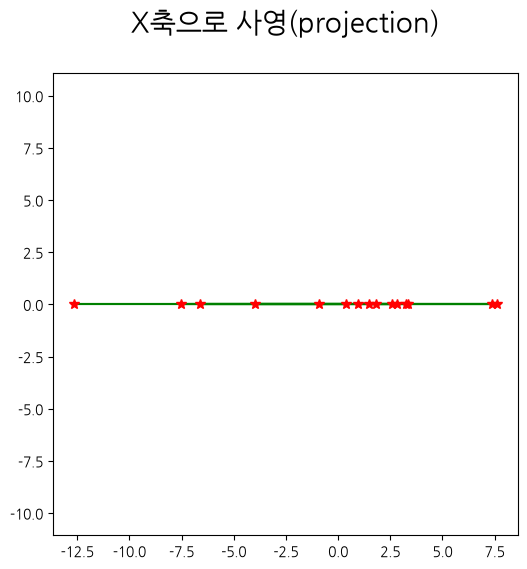

In [7]:
plt.figure(figsize=[6, 6])
plt.plot(proj2_x[:, 0], proj2_x[:, 1], 'g')
plt.plot(proj2_x[:, 0], proj2_x[:, 1], '*r', markersize=7)
plt.title('X축으로 사영(projection)', pad=30, fontsize=20)
plt.axis('equal')
plt.show()

In [8]:
# 2행 1열 벡터를 만든다. => 열이 1개이므로 열 벡터라 부른다.
# print(np.array([1, 0]).reshape(2, 1))
# 15행 2열인 2차원 배열(n_datas)을 열 벡터 [[1], [0]]와 내적하면 결과는 데이터가 15행 1열인 2차원 배열이 된다.
proj1_x = n_datas @ np.array([1, 0]).reshape(2, 1)
print(proj1_x)

[[  2.83502387]
 [ -3.96400284]
 [  0.97307882]
 [  3.26678166]
 [  7.37876759]
 [  1.80520583]
 [  1.49512954]
 [  7.59520479]
 [ -6.61568993]
 [  2.60094208]
 [ -0.90880122]
 [-12.66084402]
 [  0.35861584]
 [ -7.52279675]
 [  3.36338474]]


In [9]:
proj2_x = proj1_x @ np.array([[1, 0]])
print(proj2_x)

[[  2.83502387   0.        ]
 [ -3.96400284   0.        ]
 [  0.97307882   0.        ]
 [  3.26678166   0.        ]
 [  7.37876759   0.        ]
 [  1.80520583   0.        ]
 [  1.49512954   0.        ]
 [  7.59520479   0.        ]
 [ -6.61568993   0.        ]
 [  2.60094208   0.        ]
 [ -0.90880122   0.        ]
 [-12.66084402   0.        ]
 [  0.35861584   0.        ]
 [ -7.52279675   0.        ]
 [  3.36338474   0.        ]]


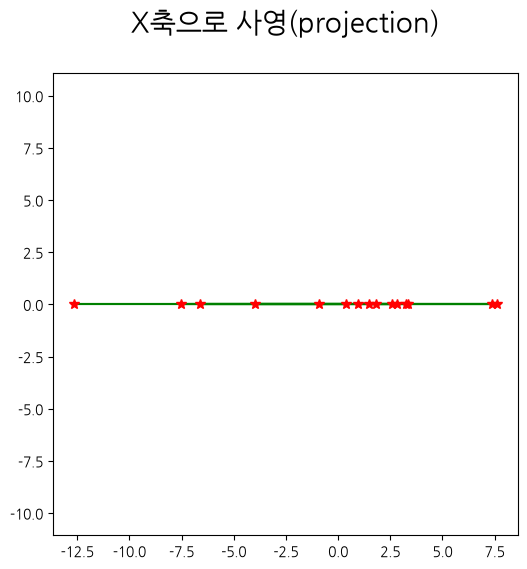

In [10]:
plt.figure(figsize=[6, 6])
plt.plot(proj2_x[:, 0], proj2_x[:, 1], 'g')
plt.plot(proj2_x[:, 0], proj2_x[:, 1], '*r', markersize=7)
plt.title('X축으로 사영(projection)', pad=30, fontsize=20)
plt.axis('equal')
plt.show()

In [11]:
# print(np.array([[1], [0]]))
proj1_x = n_datas @ np.array([[1], [0]])
print(proj1_x)

[[  2.83502387]
 [ -3.96400284]
 [  0.97307882]
 [  3.26678166]
 [  7.37876759]
 [  1.80520583]
 [  1.49512954]
 [  7.59520479]
 [ -6.61568993]
 [  2.60094208]
 [ -0.90880122]
 [-12.66084402]
 [  0.35861584]
 [ -7.52279675]
 [  3.36338474]]


In [12]:
proj2_x = proj1_x @ np.array([[1, 0]])
print(proj2_x)

[[  2.83502387   0.        ]
 [ -3.96400284   0.        ]
 [  0.97307882   0.        ]
 [  3.26678166   0.        ]
 [  7.37876759   0.        ]
 [  1.80520583   0.        ]
 [  1.49512954   0.        ]
 [  7.59520479   0.        ]
 [ -6.61568993   0.        ]
 [  2.60094208   0.        ]
 [ -0.90880122   0.        ]
 [-12.66084402   0.        ]
 [  0.35861584   0.        ]
 [ -7.52279675   0.        ]
 [  3.36338474   0.        ]]


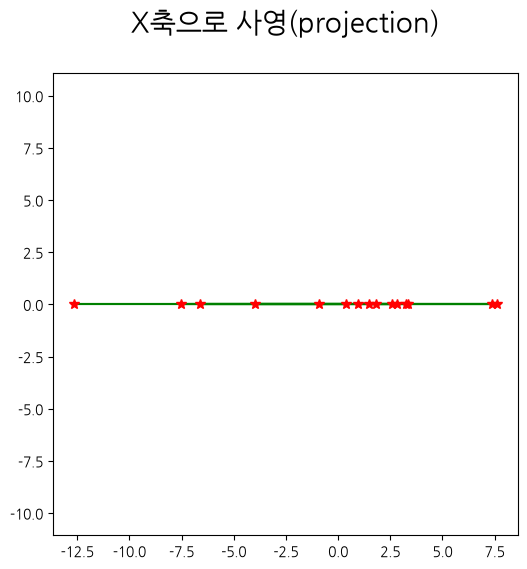

In [13]:
plt.figure(figsize=[6, 6])
plt.plot(proj2_x[:, 0], proj2_x[:, 1], 'g')
plt.plot(proj2_x[:, 0], proj2_x[:, 1], '*r', markersize=7)
plt.title('X축으로 사영(projection)', pad=30, fontsize=20)
plt.axis('equal')
plt.show()

Y축으로 사영하면 X좌표는 무시되고(0이되고) Y좌표만 남는다.

In [14]:
# print(np.array([[0], [1]]))
proj1_y = n_datas @ np.array([[0], [1]])
# print(proj1_y)
proj2_y = proj1_y @ np.array([[0, 1]])
print(proj2_y)

[[ 0.          1.93386619]
 [ 0.         -2.30285001]
 [ 0.          0.55807539]
 [ 0.          1.36073144]
 [ 0.          6.24659816]
 [ 0.          0.76571325]
 [ 0.          0.59798743]
 [ 0.          4.87921543]
 [ 0.         -4.16958717]
 [ 0.          1.43783653]
 [ 0.         -0.59781004]
 [ 0.         -8.91398476]
 [ 0.         -0.11084246]
 [ 0.         -3.71966728]
 [ 0.          2.03471791]]


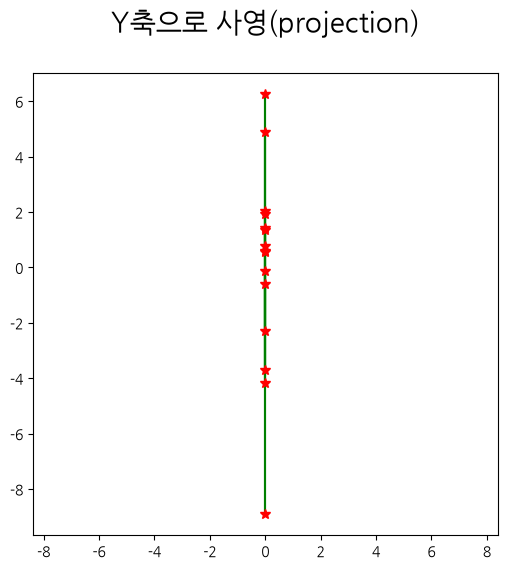

In [15]:
plt.figure(figsize=[6, 6])
plt.plot(proj2_y[:, 0], proj2_y[:, 1], 'g')
plt.plot(proj2_y[:, 0], proj2_y[:, 1], '*r', markersize=7)
plt.title('Y축으로 사영(projection)', pad=30, fontsize=20)
plt.axis('equal')
plt.show()

데이터를 임의로 설정한 선 위로 사영한다.

In [16]:
# print(np.array([[np.cos(np.pi / 6)], [np.sin(np.pi / 6)]]))
proj1 = n_datas @ np.array([[np.cos(np.pi / 6)], [np.sin(np.pi / 6)]])
# print(proj1)
proj2 = proj1 @ np.array([[np.cos(np.pi / 6), np.sin(np.pi / 6)]])
print(proj2)

[[  2.96365653   1.71106789]
 [ -3.97016544  -2.29217608]
 [  0.97146285   0.56087434]
 [  3.03930025   1.75474082]
 [  8.23893203   4.75674963]
 [  1.68546794   0.97310537]
 [  1.38028331   0.79690694]
 [  7.80916585   4.508624  ]
 [ -6.76725165  -3.90707456]
 [  2.57330804   1.48570009]
 [ -0.94046026  -0.54297498]
 [-13.35550164  -7.71080247]
 [  0.22096569   0.1275746 ]
 [ -7.25276074  -4.18738337]
 [  3.40359726   1.96506779]]


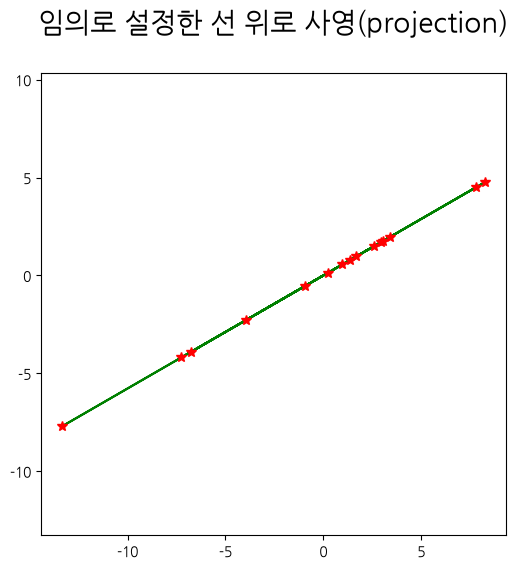

In [17]:
plt.figure(figsize=[6, 6])
plt.plot(proj2[:, 0], proj2[:, 1], 'g')
plt.plot(proj2[:, 0], proj2[:, 1], '*r', markersize=7)
plt.title('임의로 설정한 선 위로 사영(projection)', pad=30, fontsize=20)
plt.axis('equal')
plt.show()

표준편차가 큰게 데이터 과학 입장에서는 데이터의 분포를 잘 보존하고 있다고 생각할 수 있다.  
임의로 설정한 선의 표준편차가 가장 크므로 X축이나 Y축 보다는 임의의 선으로 정사영하는 것이 좋다.

In [18]:
print(np.std(proj1_x)) # X축으로 사영한 데이터의 표준편차
print(np.std(proj1_y)) # Y축으로 사영한 데이터의 표준편차
print(np.std(proj1)) # 임의의 선으로 사영한 데이터의 표준편차

5.370819478983687
3.5798906142275246
6.423864903879102


# 공분산(covariance)

두 집단의 상호 연관성(상관 관계)을 측정하는 도구로 $X$에서 $X$의 기대값(평균)을 뺀 편차에서 $Y$에서 $Y$의 기대값을 뺀 편차의 곱에 대한 기대값으로 계산한다.

$$cov=E((X-E(X))(Y-E(Y)))$$

$x=\{x_1, x_2, \ldots, x_n\}$이고 $y=\{y_1, y_2, \ldots, y_n\}$일 때 $x$와 $y$의 공분산은 아래와 같이 계산한다.

$$cov=\frac{1}{n-1} \sum_{i=1}^{n}(x_i-\bar x)(y_i-\bar y)$$

분모를 $n-1$로 계산하는 이유는 표본에 대한 공분산이기 때문이다. 만약에 모집단 전체에 대해서 공분산을 계산할 때는 $n$으로 계산한다.

$Z = \begin{bmatrix} x_1 & x_2 & \cdots x_n \\ y_1 & y_2 & \cdots y_n \end{bmatrix}$ 이고  $\bar x = \bar y=0$일 경우 공분산 행렬은 $\Sigma =\begin{bmatrix} {\rm Var}(x) & {\rm Cov}(x,y) \\ {\rm Cov}(y,x) & {\rm Var}(y) \end{bmatrix}$와 같이 계산할 수 있고 $ ZZ^T = \begin{bmatrix} \langle x, x\rangle  &\langle x, y \rangle \\ \langle y, x \rangle &\langle y, y \rangle \end{bmatrix}$와 비례한다.

In [19]:
# 넘파이의 T는 행렬을 전치(행을 열로 열은 행으로)한다.
print(n_datas.shape, n_datas.T.shape)
# 공분산 행렬을 계산한다.
print((n_datas.T @ n_datas) / (n_datas.shape[0] - 1))

(15, 2) (2, 15)
[[30.90610915 20.32420546]
 [20.32420546 13.73101801]]


넘파이에서 분산을 계산할 때 ddof(delta degree of freedom, 자유도)는 생략시 0이고 n으로 나누는것이고, 1은 (n-1)로 나누는 것(표본분산)이다.

In [20]:
print(np.var(n_datas[:, 0], ddof=1))
print(np.var(n_datas[:, 1], ddof=1))

30.906109152675644
13.731018010536776


cov() 메소드는 넘파이에서 공분산 행렬을 계산한다.

In [21]:
print(np.cov(n_datas.T, ddof=1))

[[30.90610915 20.32420546]
 [20.32420546 13.73101801]]


# PCA 예제1

In [22]:
# 공분산 행렬을 계산한다.
sigma = np.cov(n_datas.T, ddof=1)
print(sigma)
# 넘파이의 linalg.eig() 메소드에 공분산 행렬을 넘겨서 고유값과 고유 벡터 행렬를 계산한다.
las, evs = np.linalg.eig(sigma)
# las는 고유값을 의미하며 피처 개수가 2개이기 때문에 고유값도 2개가 나온다.
print(las)
# evs는 고유 벡터 행렬을 의미하여 첫 번째 열 벡터가 첫 번째 고유값에 대응되고 두 번째 열 벡트가 두 번째 고유값에 대응된다.
# 원래 데이터(n_datas) 데이터 특성의 x값에 열 벡터의 첫 번째 값을 내적하고 y값에 열 벡터의 두 번째 값을 내적한 새로운 특성을 사용하면 데이터의 분포를 거의
# 유지하면서 1차원으로 데이터를 나타낼 수 있다는 의미이다.
print(evs)

[[30.90610915 20.32420546]
 [20.32420546 13.73101801]]
[44.38254479  0.25458238]
[[ 0.83342998 -0.55262507]
 [ 0.55262507  0.83342998]]


In [23]:
proj1_pca1_x = evs[:, 0] # 첫 번째 특성 벡터, x축
print(proj1_pca1_x)
proj2_pca1_x = n_datas @ proj1_pca1_x
print(proj2_pca1_x)

[0.83342998 0.55262507]
[  3.43149683  -4.57633146   1.11939951   3.47460809   9.60171287
   1.927665     1.57654863   9.02644815  -7.81793272   2.96228761
  -1.087787   -15.47801844   0.23762687  -8.32530574   3.92758181]


넘파이의 zeros() 메소드와 zeros_like() 메소드는 내용이 모두 0인 행렬(영행렬)을 만든다.  
zeros() 메소드와 zeros_like() 메소드의 차이점은 zeros() 메소드 지정된 행, 열의 크기를 가지는 영행렬을 만들고 zeros_like() 메소드는 인수로 지정된 행렬의 크기와 같은 영행렬을 만든다.

In [24]:
print(np.zeros([4, 3]))

[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]


In [25]:
a = np.array([[1, 2], [3, 4]])
print(a)
print(np.zeros_like(a))

[[1 2]
 [3 4]]
[[0 0]
 [0 0]]


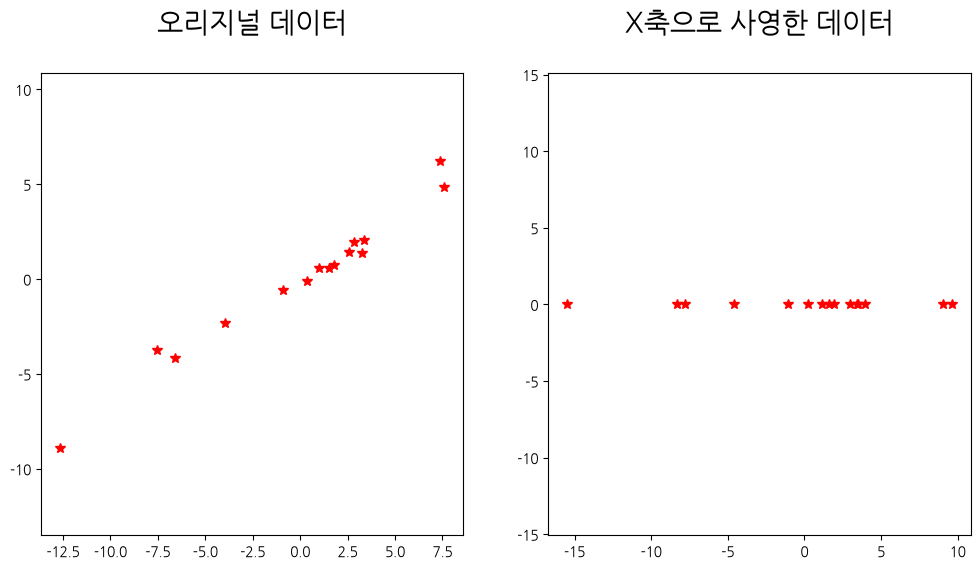

In [26]:
plt.figure(figsize=[12, 6])

plt.subplot(1, 2, 1)
plt.plot(n_datas[:, 0], n_datas[:, 1], '*r', markersize=7)
plt.title('오리지널 데이터', pad=30, fontsize=20)
plt.axis('equal')

plt.subplot(1, 2, 2)
plt.plot(proj2_pca1_x, np.zeros_like(proj2_pca1_x), '*r', markersize=7)
plt.title('X축으로 사영한 데이터', pad=30, fontsize=20)
plt.axis('equal')

plt.show()

In [27]:
proj1_pca1_y = evs[:, 1] # 두 번째 특성 벡터, y축
print(proj1_pca1_y)
proj2_pca1_y = n_datas @ proj1_pca1_y
print(proj2_pca1_y)

[-0.55262507  0.83342998]
[ 0.04503679  0.27134312 -0.07263099 -0.67123107  1.12841022 -0.35943362
 -0.32786541 -0.13081617  0.18093717 -0.23900973  0.00399353 -0.43248232
 -0.29055953  1.05720386 -0.16289582]


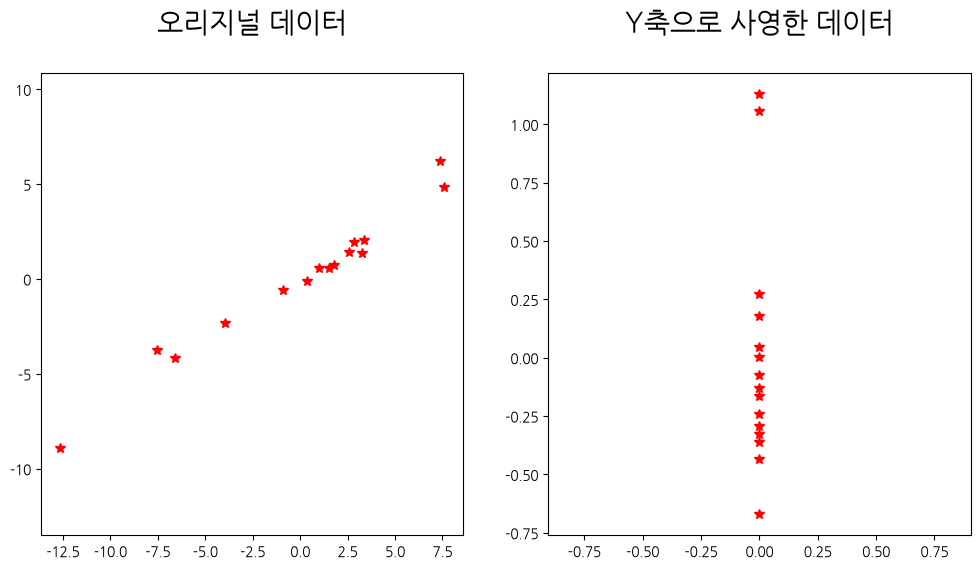

In [28]:
plt.figure(figsize=[12, 6])

plt.subplot(1, 2, 1)
plt.plot(n_datas[:, 0], n_datas[:, 1], '*r', markersize=7)
plt.title('오리지널 데이터', pad=30, fontsize=20)
plt.axis('equal')

plt.subplot(1, 2, 2)
plt.plot(np.zeros_like(proj2_pca1_x), proj2_pca1_y, '*r', markersize=7)
plt.title('Y축으로 사영한 데이터', pad=30, fontsize=20)
plt.axis('equal')

plt.show()

## 고유벡터 축으로 사영화 한다.

첫 번째 고유벡터: [0.83342998 0.55262507]
첫 번째 고유벡터 사영 값: [  3.43149683  -4.57633146   1.11939951   3.47460809   9.60171287
   1.927665     1.57654863   9.02644815  -7.81793272   2.96228761
  -1.087787   -15.47801844   0.23762687  -8.32530574   3.92758181]
두 번째 고유벡터: [-0.55262507  0.83342998]
두 번째 고유벡터 사영 값: [ 0.04503679  0.27134312 -0.07263099 -0.67123107  1.12841022 -0.35943362
 -0.32786541 -0.13081617  0.18093717 -0.23900973  0.00399353 -0.43248232
 -0.29055953  1.05720386 -0.16289582]


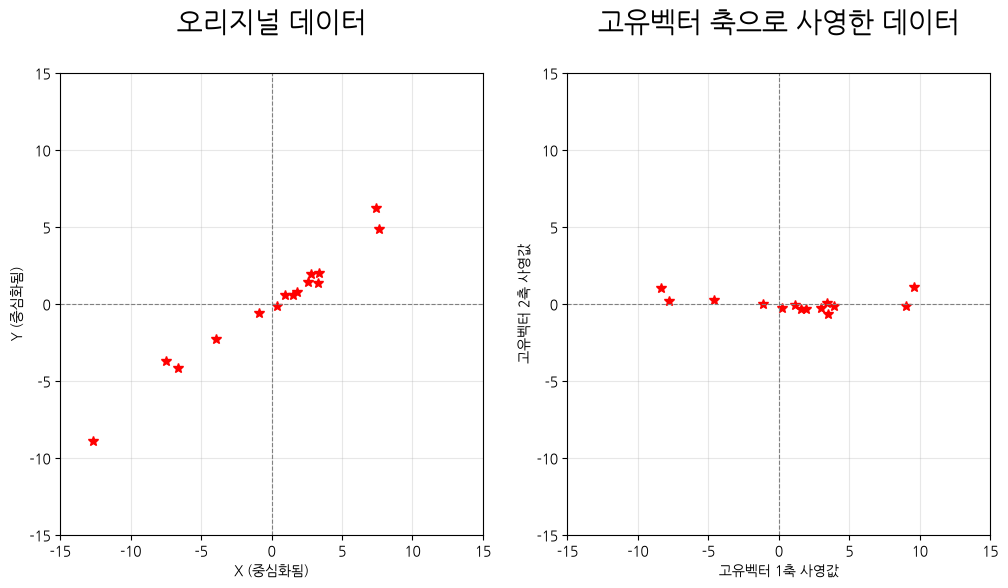

In [41]:
# 공분산 행렬 및 고유값, 고유벡터를 계산한다.
sigma = np.cov(n_datas.T, ddof=1)
las, evs = np.linalg.eig(sigma)

# 각 고유벡터 축으로 사영된 좌표를 계산한다.
proj1_pca1_x = evs[:, 0] # 첫 번째 고유벡터
print('첫 번째 고유벡터:', proj1_pca1_x)
proj2_pca1_x = n_datas @ proj1_pca1_x
print('첫 번째 고유벡터 사영 값:', proj2_pca1_x)

proj1_pca1_y = evs[:, 1] # 두 번째 고유벡터
print('두 번째 고유벡터:', proj1_pca1_y)
proj2_pca1_y = n_datas @ proj1_pca1_y
print('두 번째 고유벡터 사영 값:', proj2_pca1_y)

plt.figure(figsize=[12, 6])

plt.subplot(1, 2, 1)
plt.plot(n_datas[:, 0], n_datas[:, 1], '*r', markersize=7)
plt.axhline(0, color='gray', linewidth=0.8, linestyle='--')
plt.axvline(0, color='gray', linewidth=0.8, linestyle='--')
plt.grid(True, alpha=0.3)
plt.title('오리지널 데이터', pad=30, fontsize=20)
plt.xlabel('X (중심화됨)')
plt.ylabel('Y (중심화됨)')
plt.xlim(-15, 15)
plt.ylim(-15, 15)

plt.subplot(1, 2, 2)
plt.plot(proj2_pca1_x, proj2_pca1_y, '*r', markersize=7)
plt.axhline(0, color='gray', linewidth=0.8, linestyle='--')
plt.axvline(0, color='gray', linewidth=0.8, linestyle='--')
plt.grid(True, alpha=0.3)
plt.title('고유벡터 축으로 사영한 데이터', pad=30, fontsize=20)
plt.xlabel('고유벡터 1축 사영값')
plt.ylabel('고유벡터 2축 사영값')
plt.xlim(-15, 15)
plt.ylim(-15, 15)

plt.show()

# PCA 예제2

In [43]:
raw_data = datasets.load_digits()
print(raw_data.data.shape)

(1797, 64)


In [46]:
print(raw_data.data[0])
print(raw_data.data[0].reshape(8, 8))
print(raw_data.images[0])

[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]
[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]
[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]


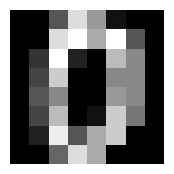

target value: 0


In [50]:
plt.figure(figsize=[2, 2])
plt.imshow(raw_data.data[0].reshape(8, 8), cmap=plt.cm.gray)
plt.axis('off')
plt.show()
print(f'target value: {raw_data.target[0]}')

In [68]:
X = raw_data.data
# print(X)
# 행렬을 전치해서 각 특징 벡터를 열벡터로 만든다.
X = X.T
# 평균이 0이 되도록 해서 중심을 맞춘다.
X = X - np.mean(X, axis=1).reshape(-1, 1)
# print(X)
# 공분산 행렬을 계산한다.
sigma = X @ X.T
# print(sigma)
# 고유값, 고유벡터를 계산한다.
las, evs = np.linalg.eig(sigma)
print(len(las))
print(las[:6])
# 처음 고유값 2개를 더한 값이 전체 고유값의 합계 중에서 28.5%를 차지하므로 피처를 2개만 사용해더라도 전체 데이터의 분산을 28.5% 보존하고 있음을 알 수 있다.
print(sum(las[:2]) / sum(las))
print(evs[:2])

64
[321496.44645596 294037.07339949 254652.03660974 181576.27386432
 124845.64540141 106158.9106958 ]
0.2850936482369927
[[ 0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          1.          0.          0.        ]
 [ 0.01730947  0.01010646 -0.01834207  0.02001291 -0.01407859 -0.00963006
  -0.00248955 -0.02264646  0.01697834  0.02487613  0.00247268 -0.00694806
   0.02681175 -0.052

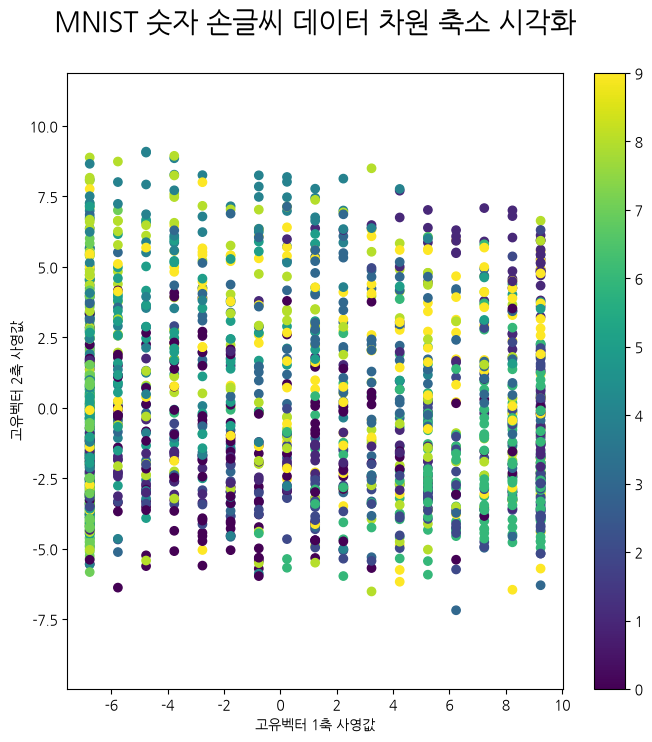

In [74]:
x = evs[0] @ X
y = evs[1] @ X

plt.figure(figsize=[8, 8])
plt.scatter(x, y, c=raw_data.target)
plt.title('MNIST 숫자 손글씨 데이터 차원 축소 시각화', pad=30, fontsize=20)
plt.xlabel('고유벡터 1축 사영값')
plt.ylabel('고유벡터 2축 사영값')
plt.colorbar()
plt.axis('equal')
plt.show()